# Demo for Simple Model

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
import pickle

## Functions for Data Generation, MLE Estimation, and EIF Calculation

In [ ]:
def s_factor(c, s):
    """
    Compute factor 1 + sum_i c^i s_{ji} for all j. Currently it supports the factor as a polynomial.
    
    Parameters
    ----------
    c : float
        Scalar parameter c.
    s : array_like, shape (J, I)
        Matrix s_(ji).

    Returns
    -------
    factor : ndarray, shape (J,)
        Computed factors for each j.
    """
    s = np.asarray(s)
    if s.ndim == 1:
        s = s[:, None]   # (J, 1)
    elif s.ndim != 2:
        raise ValueError(f"s must be 1D or 2D, got {s.shape}")

    J, I = s.shape

    powers = c ** np.arange(1, I + 1)
    factor = 1.0 + s @ powers

    return factor

def mu_matrix(c, s, v):
    """
    Compute μ_jk(c) = (1 + sum_i c^i s_{ji}) v_k for all j, k.

    Parameters
    ----------
    c : float
        Scalar parameter c.
    s : array_like, shape (J, :)
        Matrix s_(j:).
    v : array_like, shape (K,)
        Sequence (v_k), should satisfy sum(v) = 1.

    Returns
    -------
    mu : ndarray, shape (J, K)
        μ_jk(c) values.
    """
    s = np.asarray(s)
    v = np.asarray(v)
    
    if v.ndim != 1:
        raise ValueError(f"v must be 1D (K,), got {v.shape}")

    factor = s_factor(c, s)  # (J,)

    return factor[:, None] * v[None, :]
    
    #return (1.0 + c * s[:, None]) * v[None, :]

def simulate_D(c, s, v, sigma=1.0):
    """
    Simulate D_{jk} ~ N(mu_jk(c), sigma^2) with mu_jk(c) = (1 + c s_j) v_k.

    Parameters
    ----------
    c : float
    s : array-like of length J
    v : array-like of length K, should sum to 1
    sigma : float, optional
        Standard deviation of the Normal. Default is 1.0.

    Returns
    -------
    D : ndarray, shape (J, K)
        Simulated matrix of D_jk values.
    """    
    # Compute μ_jk(c)
    mu = mu_matrix(c, s, v)
    
    # Simulate D_jk ~ Normal(mu_jk, sigma)
    D = np.random.normal(loc=mu, scale=sigma)
    
    return D, mu

def log_likelihood(c, s, v, D):
    """
    Log-likelihood (up to additive constant) for D_jk ~ N(μ_jk(c), 1).

    Parameters
    ----------
    c : float
        Scalar parameter.
    s : array_like, shape (J,)
        Sequence s_j.
    v : array_like, shape (K,)
        Weights v_k, should sum to 1.
    D : array_like, shape (J, K)
        Observed data D_jk.

    Returns
    -------
    ll : float
        Log-likelihood up to an additive constant (ignores -0.5*J*K*log(2π)).
    """
    D = np.asarray(D)
    mu = mu_matrix(c, s, v)
    resid = D - mu
    # For N(mean, 1), loglik up to constant is -0.5 * sum (D - μ)^2
    return -0.5 * np.sum(resid ** 2)


def mle_c_v(D, s, init_c=0.0, init_v=None, tol=1e-6, max_iter=100, v_opt="lagrange", c_opt="scipy_optimize"):
    """
    Joint MLE of c and v via coordinate ascent.

    Parameters
    ----------
    D : array-like, shape (J, K)
        Observed matrix D_{jk}.
    s : array-like, shape (J,)
        s_j values.
    init_c : float, optional
        Initial guess for c. Defaults to 0.0.
    init_v : array-like, shape (K,), optional
        Initial guess for v. If None, use uniform.
    tol : float, optional
        Tolerance for convergence. Defaults to 1e-6.
    max_iter : int, optional
        Maximum number of iterations. Defaults to 100.
    v_opt: str, optional
        Method to optimize v ("lagrange"). Defaults to "lagrange".
    c_opt: str, optional
        Method to optimize c ("closed_form" or "scipy_optimize"). Defaults to "scipy_optimize".

    Returns
    -------
    c_hat : float
        MLE estimate of c.
    v_hat : ndarray, shape (K,)
        MLE estimate of v.
    res : OptimizeResult
        Full optimization result.
    """
    D = np.asarray(D)
    s = np.asarray(s)
    J, K = D.shape

    if init_v is None:
        v_hat = np.ones(K) / K
    else:
        v_hat = np.asarray(init_v)

    c_hat = init_c

    res = {"v_opt": v_opt, "c_opt": c_opt}

    for iteration in range(max_iter):
        # Update v given c
        A = s_factor(c_hat, s)  # (J,)
        if v_opt == "lagrange":
            b = A @ D # sum_j A_j D_jk
            denom = np.dot(A, A) # sum_j A_j^2
            lagrange_mult = (np.sum(b) - denom)/ K
            v_new = (b - lagrange_mult) / denom
        else:
            raise ValueError("Invalid v_opt method.")

        # Update c given v
        if c_opt == "scipy_optimize":
            def nll_c(x):
                c = float(x[0])
                return -log_likelihood(c, s, v_new, D)
            bounds = [(0, 10.0)]
            res = minimize(lambda c: nll_c(c), x0=np.array([c_hat], dtype=float), method='L-BFGS-B', 
                           bounds=bounds, options={"maxls": 20})
            # check if optimization was successful
            if not res.success:
                print(f"Warning: Optimization for c failed at iteration {iteration}: {res.message}")
            c_new = float(res.x[0])
        elif c_opt == "closed_form":
            if s.ndim != 1:
                raise ValueError("Closed-form update for c only implemented for 1D s.")
            #c_new = np.sum(s[:, None] * v_new[None, :] * (D - v_new[None, :])) / np.sum((s[:, None]**2) * (v_new[None, :]**2))
            # sum_{j,k} s_j v_k D_jk = s^T (D v)
            term1 = np.dot(s, D @ v_new)

            # sum_{j,k} s_j v_k^2 = (sum_j s_j)(sum_k v_k^2)
            v2_sum = np.dot(v_new, v_new)
            term2 = s.sum() * v2_sum
        
            num = term1 - term2

            # denom = (sum_j s_j^2)(sum_k v_k^2)
            denom = np.dot(s, s) * v2_sum

            c_new = num / denom
        else:
            raise ValueError("Invalid c_opt method.")

        # Check convergence
        if np.abs(c_new - c_hat) < tol and np.linalg.norm(v_new - v_hat) < tol:
            break

        c_hat = c_new
        v_hat = v_new
    
    if iteration == max_iter - 1:
        print("Warning: Coordinate ascent did not converge within the maximum number of iterations.")
    res["iterations"] = iteration + 1

    return c_hat, v_hat, res


def mle_v(D, s, c=0.0, init_v=None, v_opt="lagrange"):
    """
    MLE of v given c.

    Parameters
    ----------
    D : array-like, shape (J, K)
        Observed matrix D_{jk}.
    s : array-like, shape (J,)
        s_j values.
    c : float, optional
        Given c value. If not provided, defaults to 0.0.
    init_v : array-like, shape (K,), optional
        Initial guess for v. If None, use uniform.
    v_opt: str, optional
        Method to optimize v ("lagrange"). Defaults to "lagrange".

    Returns
    -------
    v_hat : ndarray, shape (K,)
        MLE estimate of v.
    """
    D = np.asarray(D)
    s = np.asarray(s)
    J, K = D.shape

    if init_v is None:
        init_v = np.ones(K) / K
    else:
        init_v = np.asarray(init_v)

    A = s_factor(c, s)

    if v_opt == "lagrange":
        b = A @ D # sum_j A_j D_jk
        denom = np.dot(A, A) # sum_j A_j^2
        lagrange_mult = (np.sum(b) - denom)/ K
        v_hat = (b - lagrange_mult) / denom
    else:
        raise ValueError("Invalid v_opt method.")
    
    return v_hat


def mle_c(D, s, v_hat, init_c=0.0, c_opt="scipy_optimize"):
    """
    MLE of c given v.

    Parameters
    ----------
    D : array-like, shape (J, K)
        Observed data D_{jk}.
    s : array-like, shape (J,)
        s_j values.
    v_hat : array-like, shape (K,)
        Estimated weights v_k.
    init_c : float
        Initial guess for c when using scipy_optimize.
    c_opt: str, optional
        Method to optimize c ("closed_form" or "scipy_optimize"). Defaults to "scipy_optimize".
    
    Returns
    -------
    c_plugin : float
        Plug-in estimate of c.
    """
    # Update c given v
    if c_opt == "scipy_optimize":
        def nll_c(x):
            c = float(x[0])
            return -log_likelihood(c, s, v_hat, D)
        bounds = [(0, 10.0)]
        res = minimize(lambda c: nll_c(c), x0=np.array([init_c], dtype=float), method='L-BFGS-B', 
                        bounds=bounds, options={"maxls": 20})
        # check if optimization was successful
        if not res.success:
            print(f"Warning: Optimization for c failed: {res.message}")
        c_plugin = float(res.x[0])
    elif c_opt == "closed_form":
        if s.ndim != 1:
            raise ValueError("Closed-form update for c only implemented for 1D s.")
        # sum_{j,k} s_j v_k D_jk = s^T (D v)
        term1 = np.dot(s, D @ v_hat)

        # sum_{j,k} s_j v_k^2 = (sum_j s_j)(sum_k v_k^2)
        v2_sum = np.dot(v_hat, v_hat)
        term2 = s.sum() * v2_sum
    
        num = term1 - term2

        # denom = (sum_j s_j^2)(sum_k v_k^2)
        denom = np.dot(s, s) * v2_sum

        c_plugin = num / denom
    else:
        raise ValueError("Invalid c_opt method.")
    return c_plugin


def compute_c_one_step_s1d(D, s, v_hat, c_hat):
    """
    One-step estimator for c when s is 1D (i.e., the factor is linear: 1 + c s_j).

    Parameters
    ----------
    D : array-like, shape (J, K)
        Observed data D_{jk}.
    s : array-like, shape (J,)
        s_j values.
    v_hat : array-like, shape (K,)
        Estimated v_k.
    c_hat : float
        Estimated c.
    Returns
    -------
    c_one_step : float
        One-step updated estimate of c.
    """

    mu_hat = mu_matrix(c_hat, s, v_hat)  # (J, K)
    numer = np.sum((D - mu_hat) / (1 + c_hat * s[:, None]))  # scalar
    denom = np.sum(s[:, None] * v_hat[None, :] / ((1 + c_hat * s[:, None]) ** 1))  # scalar
    eif = numer / denom
    if denom < 1e-8:
        print(f"Warning: Denominator in one-step update is less than 1e-8.")
    c_one_step = c_hat + eif
    return c_one_step, eif


def compute_c_one_step(D, s, v_hat, c_hat):
    """
    One-step estimator for c for general s (i.e., the factor is polynomial: 1 + sum_i c^i s_{ji}).

    Parameters
    ----------
    D : array-like, shape (J, K)
        Observed data D_{jk}.
    s : array-like, shape (J, I)
        s_(ji) values.
    v_hat : array-like, shape (K,)
        Estimated v_k.
    c_hat : float
        Estimated c.
    Returns
    -------
    c_one_step : float
        One-step updated estimate of c.
    """
    mu_hat = mu_matrix(c_hat, s, v_hat)  # (J, K)
    Z = D - mu_hat  # (J, K)
    K = mu_hat.shape[1]

    s = np.asarray(s)
    if s.ndim == 1:
        s = s[:, None]   # (J, 1)
    elif s.ndim != 2:
        raise ValueError(f"s must be 1D or 2D, got {s.shape}")
    J, I = s.shape

    # m(c,s_j)
    m = s_factor(c_hat, s)                 # (J,)

    # m'(c,s_j)
    powers = np.arange(1, I + 1)                          # (I,)
    mprime = s @ (powers * (c_hat ** (powers - 1)))       # (J,)

    numer = np.sum(Z / m[:, None])
    denom = np.sum((mprime[:, None] * v_hat[None, :]) / m[:, None])

    if abs(denom) < 1e-8:
        raise ValueError("Denominator in EIF computation is less than 1e-8.")
    eif = numer / denom
    
    c_one_step = c_hat + eif
    return c_one_step, eif



## Toy Example

In [8]:
# specify the number of s_j and v_k
J, K = 1000, 10000

# ground truth c, s, v
c = 3
s = np.linspace(1, 2, J)
#s = np.random.uniform(0, 10, J)
#s = 100 / (np.arange(1, J + 1))
#x = np.linspace(1, 2, J)
#s = np.column_stack([
#    x,        # s_{j1}
#    x      # s_{j2}
#])
#s = (x-1.5)**2

#v = np.linspace(0, 1, K)
#v = (np.arange(1, K + 1)) ** (-1/2)
#v = 1 / (np.arange(1, K + 1))
#v = np.random.uniform(0, 1, K)
#v = np.repeat(1/K, K)
v = (np.linspace(0, 1, K) - 0.5)**2
v /= np.sum(v)

# simulate D_jk
D, mu = simulate_D(c, s, v, sigma=0.001)


Text(0.5, 1.0, 'Heatmap of True μ_jk(c) Values')

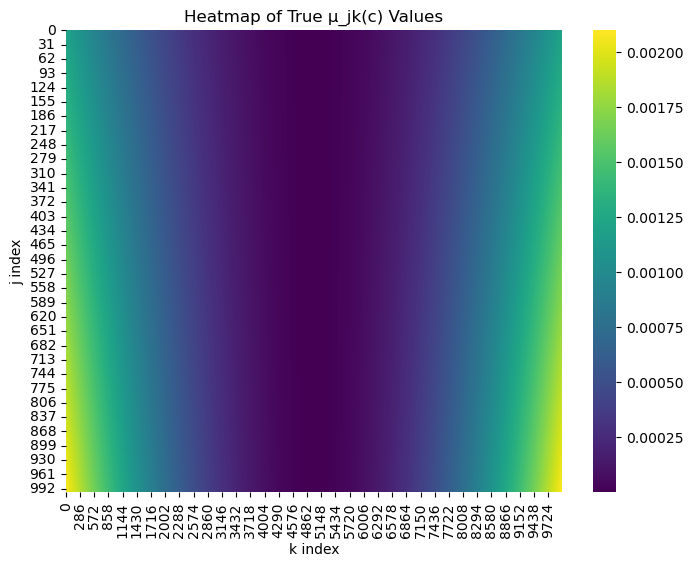

In [9]:
# plot the true mu using heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(mu, cmap="viridis")
plt.xlabel("k index")
plt.ylabel("j index")
plt.title("Heatmap of True μ_jk(c) Values")

Text(0.5, 1.0, 'Heatmap of Simulated D_jk Values')

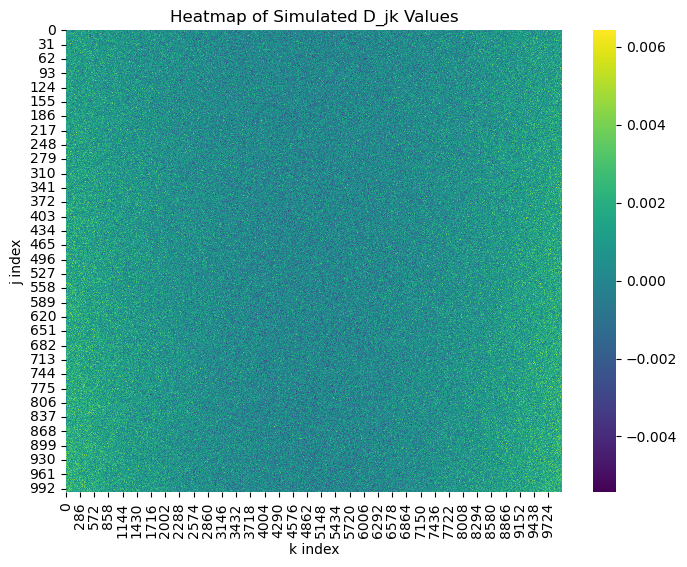

In [10]:
# plot the simulated D using heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(D, cmap="viridis")
plt.xlabel("k index")
plt.ylabel("j index")
plt.title("Heatmap of Simulated D_jk Values")

In [11]:
c_hat_ca, v_hat_ca,_ = mle_c_v(D, s, tol=1e-5, init_c=0, max_iter=5000, c_opt="scipy_optimize", v_opt="lagrange")
print("Joint MLE Estimated c:", c_hat_ca)

v_hat = mle_v(D, s, c=0, v_opt="lagrange")
c_hat = mle_c(D, s, v_hat, c_opt="scipy_optimize")
print("Plug-in Estimated c:", c_hat)


Joint MLE Estimated c: 3.0021084401919325
Plug-in Estimated c: 0.13721697506465216


Text(0.5, 1.0, 'Scatterplot of Estimated v_hat_k vs True v_k')

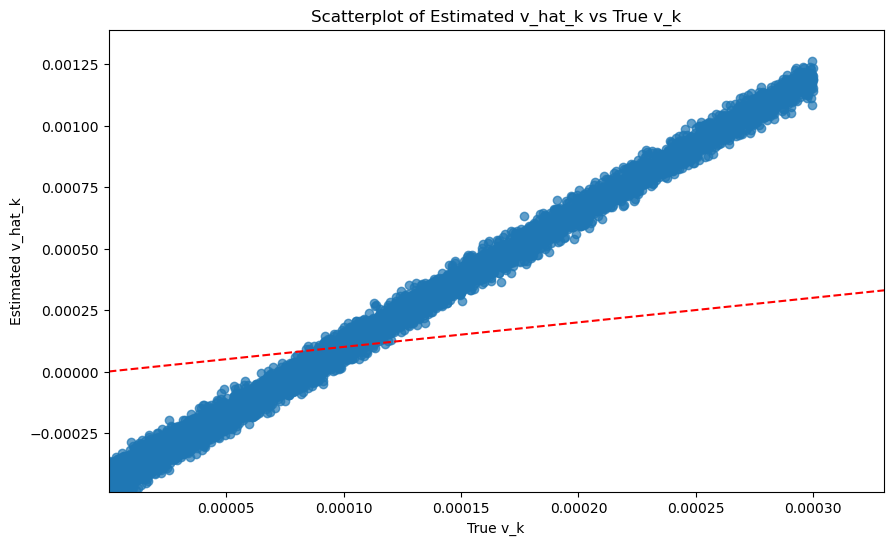

In [12]:
# plot the estimated v_hat against true v
plt.figure(figsize=(10, 6))
plt.scatter(v, v_hat, alpha=0.7)
# y=x line
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel("True v_k")
plt.ylabel("Estimated v_hat_k")
plt.xlim(np.min(v)*0.9, np.max(v)*1.1)
plt.ylim(np.min(v_hat)*0.9, np.max(v_hat)*1.1)
plt.title("Scatterplot of Estimated v_hat_k vs True v_k")

In [13]:
# one-step estimator
c_one_step, eif = compute_c_one_step(D, s, v_hat, c_hat)
print("One-step estimated c:", c_one_step)

One-step estimated c: 3.0021636990631784


## Simulation Study

In [105]:
c = 3
init_c = 0
J = 1000
#s = np.array([1,2])
#s = np.linspace(1, 2, J)
#x = np.linspace(1, 2, J)
#s = np.column_stack([
#    x,        # s_{j1}
#    x/10,         # s_{j2}
#])
# have a quadratic function s between 1 and 2
x = np.linspace(1, 2, J)
s = (x - 1.5)**2

c_opt = "scipy_optimize"
v_opt = "lagrange"
K_values = np.linspace(1000, 10000, 10, dtype=int)
sigma=0.001
v_vectors = []
N_sim = 1000

In [106]:
c_hat_values = []
c_hat_mean = []
c_hat_bias = []
c_hat_var = []
c_hat_mse = []
c_one_step_values = []
c_one_step_mean = []
c_one_step_bias = []
c_one_step_var = []
c_one_step_mse = []

# Simulation to estimate bias, variance, and MSE of c_hat for different K
for K in K_values:
    c_hat_rep = []
    c_one_step_rep = []
    v = np.linspace(0, 1, K)
    #v = 1 / (np.arange(1, K + 1))
    #v = np.random.uniform(0, 1, K)
    #v = (np.linspace(0, 1, K) - 0.5)**2
    v /= np.sum(v)
    v_vectors.append(v)

    for sim in range(N_sim):

        D, mu = simulate_D(c, s, v, sigma=sigma)
        #c_hat, v_hat, _ = mle_c_v(D, s, tol=1e-4, v_opt=v_opt, c_opt=c_opt, init_c=init_c, max_iter=15000)
        v_hat = mle_v(D, s, c=init_c, v_opt=v_opt)
        c_hat = mle_c(D, s, v_hat, c_opt=c_opt, init_c=init_c)

        c_hat_rep.append(c_hat)
        c_one_step, _ = compute_c_one_step(D, s, v_hat, c_hat)
        c_one_step_rep.append(c_one_step)

    c_hat_rep = np.array(c_hat_rep)
    c_one_step_rep = np.array(c_one_step_rep)
    c_hat_values.append(c_hat_rep)
    c_one_step_values.append(c_one_step_rep)

    mean_hat = np.mean(c_hat_rep)
    bias_hat = mean_hat - c
    var_hat = np.var(c_hat_rep, ddof=1)
    mse_hat = np.mean((c_hat_rep - c) ** 2)

    c_hat_mean.append(mean_hat)
    c_hat_bias.append(bias_hat)
    c_hat_var.append(var_hat)
    c_hat_mse.append(mse_hat)

    mean_one_step = np.mean(c_one_step_rep)
    bias_one_step = mean_one_step - c
    var_one_step = np.var(c_one_step_rep, ddof=1)
    mse_one_step = np.mean((c_one_step_rep - c) ** 2)

    c_one_step_mean.append(mean_one_step)
    c_one_step_bias.append(bias_one_step)
    c_one_step_var.append(var_one_step)
    c_one_step_mse.append(mse_one_step)

    print(
        f"\nK = {K}\n"
        f"  MLE:\n"
        f"    mean = {mean_hat:.4f}\n"
        f"    bias = {bias_hat:.4f}\n"
        f"    var  = {var_hat:.4e}\n"
        f"    mse  = {mse_hat:.4e}\n"
        f"  One-step:\n"
        f"    mean = {mean_one_step:.4f}\n"
        f"    bias = {bias_one_step:.4f}\n"
        f"    var  = {var_one_step:.4e}\n"
        f"    mse  = {mse_one_step:.4e}"
    )



K = 1000
  MLE:
    mean = 2.3351
    bias = -0.6649
    var  = 4.7435e-05
    mse  = 4.4214e-01
  One-step:
    mean = 3.0003
    bias = 0.0003
    var  = 1.9184e-04
    mse  = 1.9176e-04

K = 2000
  MLE:
    mean = 2.3304
    bias = -0.6696
    var  = 9.1907e-05
    mse  = 4.4843e-01
  One-step:
    mean = 2.9995
    bias = -0.0005
    var  = 3.6733e-04
    mse  = 3.6718e-04

K = 3000
  MLE:
    mean = 2.3236
    bias = -0.6764
    var  = 1.3695e-04
    mse  = 4.5768e-01
  One-step:
    mean = 3.0007
    bias = 0.0007
    var  = 5.8070e-04
    mse  = 5.8061e-04

K = 4000
  MLE:
    mean = 2.3126
    bias = -0.6874
    var  = 1.7806e-04
    mse  = 4.7264e-01
  One-step:
    mean = 2.9993
    bias = -0.0007
    var  = 8.0934e-04
    mse  = 8.0899e-04

K = 5000
  MLE:
    mean = 2.2994
    bias = -0.7006
    var  = 2.2302e-04
    mse  = 4.9112e-01
  One-step:
    mean = 3.0004
    bias = 0.0004
    var  = 9.2716e-04
    mse  = 9.2637e-04

K = 6000
  MLE:
    mean = 2.2836
    bias = -0

In [104]:
# Save the results into pickle file

result = {
    "J": J,
    "K_values": K_values,
    "s": s,
    "sigma": sigma,
    "N_sim": N_sim,
    "true_v": v_vectors,
    "true_c": c,
    "init_c": init_c,
    "c_hat": c_hat_values,
    "c_one_step": c_one_step_values,
    "c_hat_mean": c_hat_mean,
    "c_hat_bias": c_hat_bias,
    "c_hat_var": c_hat_var,
    "c_hat_mse": c_hat_mse,
    "c_one_step_mean": c_one_step_mean,
    "c_one_step_bias": c_one_step_bias,
    "c_one_step_var": c_one_step_var,
    "c_one_step_mse": c_one_step_mse,
    "c_opt": c_opt,
    "v_opt": v_opt}

with open(f"simulation_results/plug-in/s_quadratic_v_even_spaced/c={c}_J={J}_s=1-2_K={min(K_values)}-{max(K_values)}_v=0-1_sigma={sigma}_init_c={init_c}_c_opt={c_opt}_v_opt={v_opt}.pkl", "wb") as f:
    pickle.dump(result, f)

In [164]:
# read the results from pickle file
with open("simulation_results/plug-in/s_v_quadratic/c=3_J=100_s=1-2_K=1000-10000_v=0-1_sigma=0.001_init_c=0_c_opt=closed_form_v_opt=lagrange.pkl", "rb") as f:
    result = pickle.load(f)

K_values = result["K_values"]
J = result["J"] if "J" in result else None
s = result["s"] if "s" in result else None
N_sim = result["N_sim"] if "N_sim" in result else None
sigma = result["sigma"] if "sigma" in result else None
c = result["true_c"] if "true_c" in result else None
v_vectors = result["true_v"] if "true_v" in result else None
c_hat_values = result["c_hat"] if "c_hat" in result else None
c_hat_mean = result["c_hat_mean"] if "c_hat_mean" in result else None
c_hat_bias = result["c_hat_bias"] if "c_hat_bias" in result else None
c_hat_var = result["c_hat_var"] if "c_hat_var" in result else None
c_hat_mse = result["c_hat_mse"] if "c_hat_mse" in result else None
c_one_step_values = result["c_one_step"] if "c_one_step" in result else None
c_one_step_mean = result["c_one_step_mean"] if "c_one_step_mean" in result else None
c_one_step_bias = result["c_one_step_bias"] if "c_one_step_bias" in result else None
c_one_step_var = result["c_one_step_var"] if "c_one_step_var" in result else None
c_one_step_mse = result["c_one_step_mse"] if "c_one_step_mse" in result else None

In [156]:
# print the results
for i, K in enumerate(K_values):
    print(
        f"\nK = {K}\n"
        f"  MLE:\n"
        f"    mean = {c_hat_mean[i]:.4f}\n"
        f"    bias = {c_hat_bias[i]:.4f}\n"
        f"    var  = {c_hat_var[i]:.4e}\n"
        f"    mse  = {c_hat_mse[i]:.4e}\n"
        f"  One-step:\n"
        f"    mean = {c_one_step_mean[i]:.4f}\n"
        f"    bias = {c_one_step_bias[i]:.4f}\n"
        f"    var  = {c_one_step_var[i]:.4e}\n"
        f"    mse  = {c_one_step_mse[i]:.4e}"
    )


K = 1000
  MLE:
    mean = 2.3168
    bias = -0.6832
    var  = 4.1088e-04
    mse  = 4.6724e-01
  One-step:
    mean = 3.0022
    bias = 0.0022
    var  = 1.9300e-03
    mse  = 1.9327e-03

K = 2000
  MLE:
    mean = 2.2740
    bias = -0.7260
    var  = 7.9272e-04
    mse  = 5.2784e-01
  One-step:
    mean = 3.0027
    bias = 0.0027
    var  = 3.6928e-03
    mse  = 3.6966e-03

K = 3000
  MLE:
    mean = 2.2024
    bias = -0.7976
    var  = 1.2876e-03
    mse  = 6.3738e-01
  One-step:
    mean = 3.0032
    bias = 0.0032
    var  = 5.2347e-03
    mse  = 5.2398e-03

K = 4000
  MLE:
    mean = 2.1098
    bias = -0.8902
    var  = 1.5534e-03
    mse  = 7.9395e-01
  One-step:
    mean = 2.9994
    bias = -0.0006
    var  = 6.8283e-03
    mse  = 6.8218e-03

K = 5000
  MLE:
    mean = 2.0047
    bias = -0.9953
    var  = 1.7929e-03
    mse  = 9.9234e-01
  One-step:
    mean = 3.0030
    bias = 0.0030
    var  = 8.4869e-03
    mse  = 8.4873e-03

K = 6000
  MLE:
    mean = 1.8897
    bias = -1.

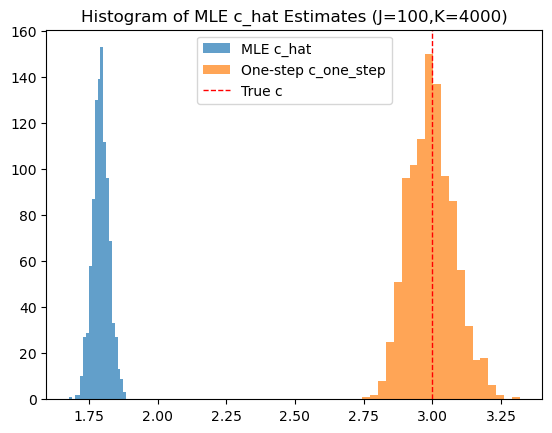

In [165]:
K_idx = 3
plt.hist(c_hat_values[K_idx], bins=20, alpha=0.7, label='MLE c_hat')
plt.hist(c_one_step_values[K_idx], bins=20, alpha=0.7, label='One-step c_one_step')
plt.axvline(x=c, color='red', linestyle='dashed', linewidth=1, label='True c')
plt.title(f'Histogram of MLE c_hat Estimates (J={J},K={K_values[K_idx]})')
plt.legend()

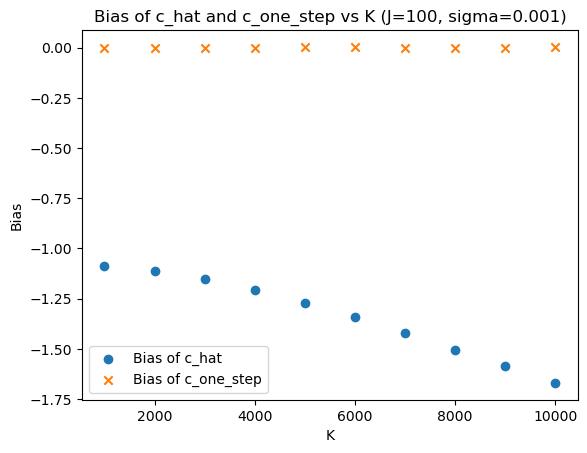

In [163]:
plt.scatter(K_values, c_hat_bias, label='Bias of c_hat')
plt.scatter(K_values, c_one_step_bias, label='Bias of c_one_step', marker='x')
plt.title(f"Bias of c_hat and c_one_step vs K (J={J}, sigma={sigma})")
plt.xlabel("K")
plt.ylabel("Bias")
plt.legend()